EDA-Reflection-Project
This is the Exploratory Data Analysis Project I created after learning EDA, for reflection and application of the skills I have acquire.

DATA DESCRIPTION:

The dataset is on hotel booking demand in 2019, 


PART A: DATA PREPROCESSING

In [39]:
#Import data
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df_org=pd.read_csv(r"C:\Users\Lenovo\Desktop\CODING\EDA Reflection Projects _ Main Work\hotel_bookings.csv")
df_org.head(50)

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,1/7/2015
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,1/7/2015
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.00,0,0,Check-Out,2/7/2015
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.00,0,0,Check-Out,2/7/2015
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,3/7/2015
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,3/7/2015
6,Resort Hotel,0,0,2015,July,27,1,0,2,2,...,No Deposit,NaN,NaN,0,Transient,107.00,0,0,Check-Out,3/7/2015
7,Resort Hotel,0,9,2015,July,27,1,0,2,2,...,No Deposit,303.0,NaN,0,Transient,103.00,0,1,Check-Out,3/7/2015
8,Resort Hotel,1,85,2015,July,27,1,0,3,2,...,No Deposit,240.0,NaN,0,Transient,82.00,0,1,Canceled,6/5/2015
9,Resort Hotel,1,75,2015,July,27,1,0,3,2,...,No Deposit,15.0,NaN,0,Transient,105.50,0,0,Canceled,22-04-15


In [45]:
df_org.query("customer_type=='Group'")

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
539,Resort Hotel,0,0,2015,July,30,19,1,0,2,...,No Deposit,240.0,NaN,0,Group,98.0,1,0,Check-Out,20-07-15
541,Resort Hotel,0,0,2015,July,30,19,1,0,2,...,No Deposit,NaN,240.0,0,Group,88.2,0,0,Check-Out,20-07-15
1156,Resort Hotel,0,0,2015,August,34,16,1,0,2,...,No Deposit,240.0,NaN,0,Group,195.0,0,0,Check-Out,17-08-15
1539,Resort Hotel,1,304,2015,September,36,3,0,3,40,...,No Deposit,NaN,NaN,0,Group,0.0,0,0,Canceled,2/1/2015
1587,Resort Hotel,1,333,2015,September,36,5,2,5,26,...,No Deposit,96.0,NaN,0,Group,0.0,0,0,Canceled,2/1/2015
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
116048,City Hotel,0,468,2017,July,30,29,2,1,1,...,No Deposit,229.0,NaN,0,Group,0.0,0,0,Check-Out,1/8/2017
116809,City Hotel,0,76,2017,August,32,6,2,0,3,...,No Deposit,14.0,NaN,0,Group,179.5,0,1,Check-Out,8/8/2017
118165,City Hotel,0,3,2017,August,32,6,4,6,2,...,No Deposit,20.0,NaN,0,Group,89.0,0,0,Check-Out,16-08-17
118581,City Hotel,0,11,2017,August,34,25,0,2,2,...,No Deposit,98.0,NaN,0,Group,125.0,0,0,Check-Out,27-08-17


In [36]:
#Check for group booking by adult number and children number of customers
df_org["adults"].value_counts()

adults
2     89680
1     23027
3      6202
0       403
4        62
26        5
27        2
20        2
5         2
40        1
50        1
55        1
6         1
10        1
Name: count, dtype: int64

In [2]:
df_org.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='str')

In [3]:
df=df_org.drop(["company","agent",'stays_in_weekend_nights',
       'stays_in_week_nights', 'meal',
       'country','adults', 'children', 'babies',"distribution_channel","booking_changes",
"assigned_room_type",
"days_in_waiting_list",
"total_of_special_requests",
"required_car_parking_spaces",
"reservation_status","arrival_date_week_number","arrival_date_day_of_month","arrival_date_year","adr","reservation_status_date","reserved_room_type"
],axis=1)

In [4]:
df["market_segment"].unique()

<StringArray>
[       'Direct',     'Corporate',     'Online TA', 'Offline TA/TO',
 'Complementary',        'Groups',     'Undefined',      'Aviation']
Length: 8, dtype: str

In [5]:
df_org["distribution_channel"].unique()

<StringArray>
['Direct', 'Corporate', 'TA/TO', 'Undefined', 'GDS']
Length: 5, dtype: str

In [6]:
df["is_repeated_guest"].unique()

array([0, 1])

In [7]:
df["deposit_type"].unique()

<StringArray>
['No Deposit', 'Refundable', 'Non Refund']
Length: 3, dtype: str

In [8]:
df["customer_type"].unique()

<StringArray>
['Transient', 'Contract', 'Transient-Party', 'Group']
Length: 4, dtype: str

In [9]:
df["is_canceled"]=df["is_canceled"].astype(str)
df["is_canceled"].dtypes

<StringDtype(storage='python', na_value=nan)>

In [38]:
df.head(10)

,hotel,is_canceled,lead_time,arrival_date_month,market_segment,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,deposit_type,customer_type
0,Resort Hotel,0,342,July,Direct,0,0,0,No Deposit,Transient
1,Resort Hotel,0,737,July,Direct,0,0,0,No Deposit,Transient
2,Resort Hotel,0,7,July,Direct,0,0,0,No Deposit,Transient
3,Resort Hotel,0,13,July,Corporate,0,0,0,No Deposit,Transient
4,Resort Hotel,0,14,July,Online TA,0,0,0,No Deposit,Transient
5,Resort Hotel,0,14,July,Online TA,0,0,0,No Deposit,Transient
6,Resort Hotel,0,0,July,Direct,0,0,0,No Deposit,Transient
7,Resort Hotel,0,9,July,Direct,0,0,0,No Deposit,Transient
8,Resort Hotel,1,85,July,Online TA,0,0,0,No Deposit,Transient
9,Resort Hotel,1,75,July,Offline TA/TO,0,0,0,No Deposit,Transient


In [11]:
#Data understanding
df.dtypes
df=df.dropna()
#Remember to assign the df to the new df after dropping the null values, otherwise it will not be saved
df.isna().sum()

hotel                             0
is_canceled                       0
lead_time                         0
arrival_date_month                0
market_segment                    0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
deposit_type                      0
customer_type                     0
dtype: int64

In [12]:
df.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_month',
       'market_segment', 'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'deposit_type', 'customer_type'],
      dtype='str')

In [13]:
#Handling duplicates: (very ass)
df_org[df_org.duplicated(keep=False)]
#Since the dataset has no booking ID, it canot be concluded that the repeated rows are duplicates. Therefore, we will do 2 analysis, however, the without duplicates dataset will be more prioritized for insights. The dataset without duplicates is df1, the dataset with duplicates is df2.

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,3/7/2015
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,3/7/2015
21,Resort Hotel,0,72,2015,July,27,1,2,4,2,...,No Deposit,250.0,NaN,0,Transient,84.67,0,1,Check-Out,7/7/2015
22,Resort Hotel,0,72,2015,July,27,1,2,4,2,...,No Deposit,250.0,NaN,0,Transient,84.67,0,1,Check-Out,7/7/2015
39,Resort Hotel,0,70,2015,July,27,2,2,3,2,...,No Deposit,250.0,NaN,0,Transient,137.00,0,1,Check-Out,7/7/2015
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119352,City Hotel,0,63,2017,August,35,31,0,3,3,...,No Deposit,9.0,NaN,0,Transient-Party,195.33,0,2,Check-Out,3/9/2017
119353,City Hotel,0,63,2017,August,35,31,0,3,3,...,No Deposit,9.0,NaN,0,Transient-Party,195.33,0,2,Check-Out,3/9/2017
119354,City Hotel,0,63,2017,August,35,31,0,3,3,...,No Deposit,9.0,NaN,0,Transient-Party,195.33,0,2,Check-Out,3/9/2017
119372,City Hotel,0,175,2017,August,35,31,1,3,1,...,No Deposit,42.0,NaN,0,Transient,82.35,0,1,Check-Out,4/9/2017


In [14]:
df[df.duplicated(keep=False)]

,hotel,is_canceled,lead_time,arrival_date_month,market_segment,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,deposit_type,customer_type
2,Resort Hotel,0,7,July,Direct,0,0,0,No Deposit,Transient
3,Resort Hotel,0,13,July,Corporate,0,0,0,No Deposit,Transient
4,Resort Hotel,0,14,July,Online TA,0,0,0,No Deposit,Transient
5,Resort Hotel,0,14,July,Online TA,0,0,0,No Deposit,Transient
6,Resort Hotel,0,0,July,Direct,0,0,0,No Deposit,Transient
...,...,...,...,...,...,...,...,...,...,...
119385,City Hotel,0,23,August,Offline TA/TO,0,0,0,No Deposit,Transient
119386,City Hotel,0,102,August,Online TA,0,0,0,No Deposit,Transient
119387,City Hotel,0,34,August,Online TA,0,0,0,No Deposit,Transient
119388,City Hotel,0,109,August,Online TA,0,0,0,No Deposit,Transient


array([[<Axes: title={'center': 'lead_time'}>,
        <Axes: title={'center': 'is_repeated_guest'}>],
       [<Axes: title={'center': 'previous_cancellations'}>,
        <Axes: title={'center': 'previous_bookings_not_canceled'}>]],
      dtype=object)

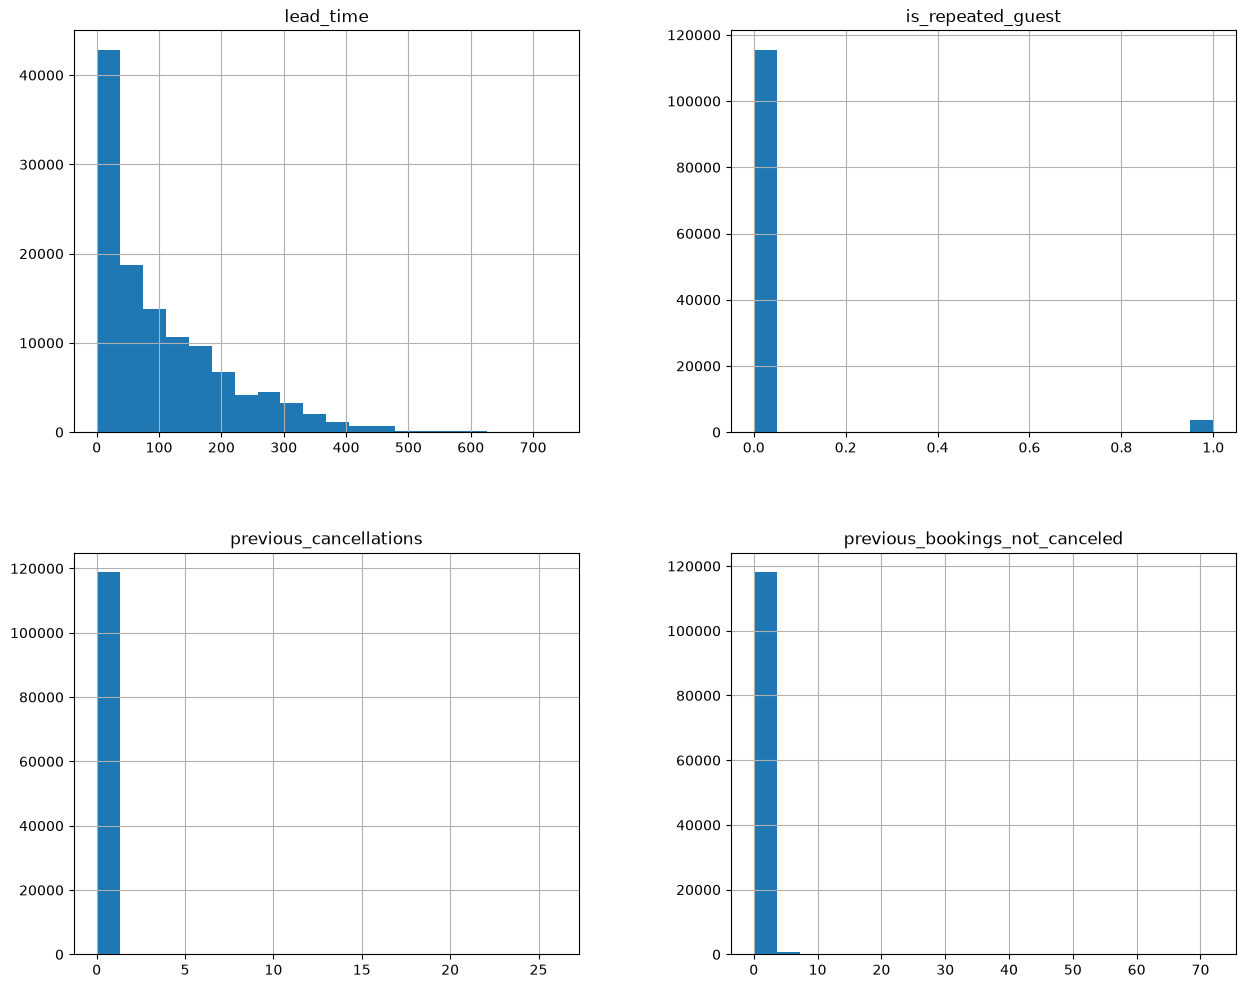

In [15]:
df.hist(bins=20,figsize=(15,12))

PART B: Exploratory Data Analysis

In [16]:
df.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_month',
       'market_segment', 'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'deposit_type', 'customer_type'],
      dtype='str')

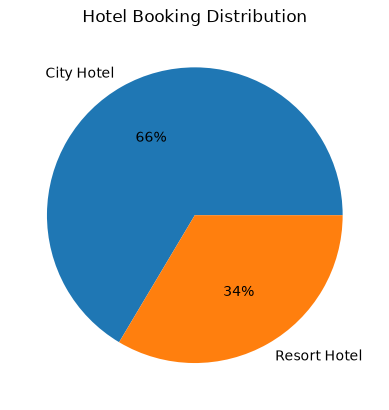

In [17]:
#Univariate Analysis
#Hotel Booking Distribution
hotel_counts=df["hotel"].value_counts()
plt.pie(hotel_counts,labels=hotel_counts.index,autopct="%1.0f%%")
plt.title("Hotel Booking Distribution")
plt.show()
#City hotels account for 66% of the bookings, indicate that the data is more focused on "urban travellers".

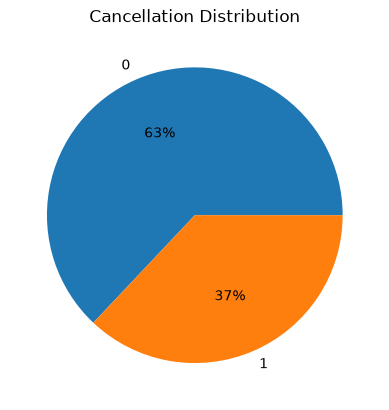

In [18]:
#Class balance: Cancellation
cancellation_count=df["is_canceled"].value_counts()
plt.pie(cancellation_count,labels=cancellation_count.index,autopct="%1.0f%%")
plt.title("Cancellation Distribution")
plt.show()
#0: not canceled, 1: canceled

37% of the bookings are cancelled, representing a substantial revenue risk for the hotel.

<Axes: xlabel='lead_time'>

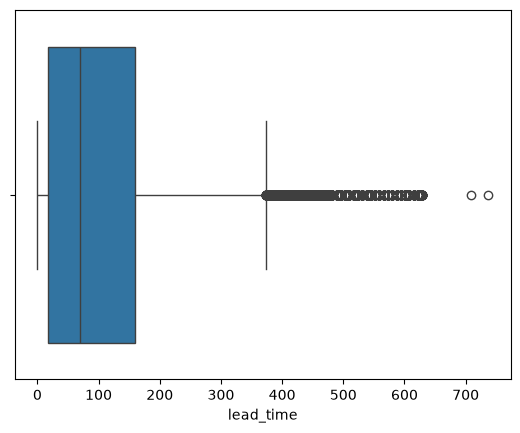

In [19]:
#LEAD TIME
sns.boxplot(x=df["lead_time"])

The boxplot shows that the lead_time (the duration between the booking date and the arrival date) is very right-skewed. -The median is around 70-80 days (the line): Typical customers book 70-80 days in advanced
-The blue box ranges from 30 to 160 days: The majority of customers book 30-160 days in advanced
-->The lead_time varies a lot

-Numerous right-skewed outliers exist: a small number of people book exceptionally early, more than a year in advanced, creating the right-skewed distribution (median != mean)

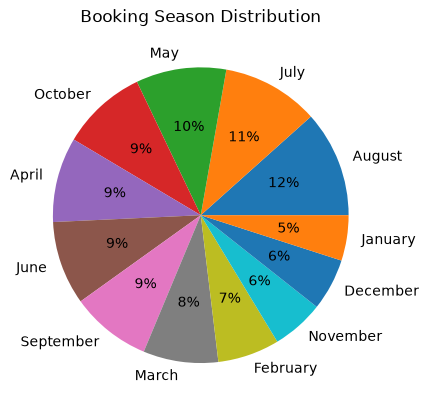

In [20]:
#Booking Season
month_arrived=df["arrival_date_month"].value_counts()
plt.pie(month_arrived,labels=month_arrived.index,autopct="%1.0f%%")
plt.title("Booking Season Distribution")
plt.show()

August and July has the highest booking volume, suggesting strong summer seasonality

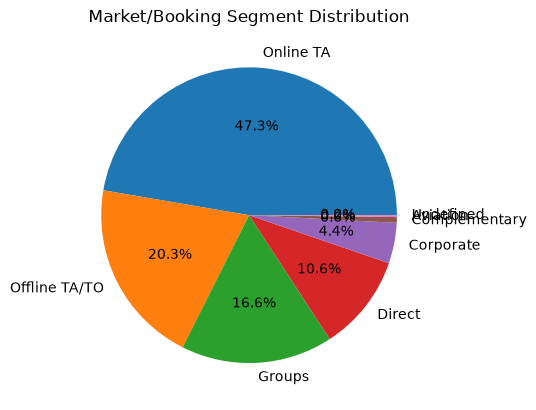

In [21]:
#Booking Channel
market_segment=df["market_segment"].value_counts()
plt.pie(market_segment,labels=market_segment.index,autopct="%1.1f%%")
plt.title("Market/Booking Segment Distribution")
plt.show()

Online Travel Agent holds the largest share, indicating that the majority of customer chooses online travel agency (Traveloka, Booking.com,...) to book their vacations, following by offline TA. 

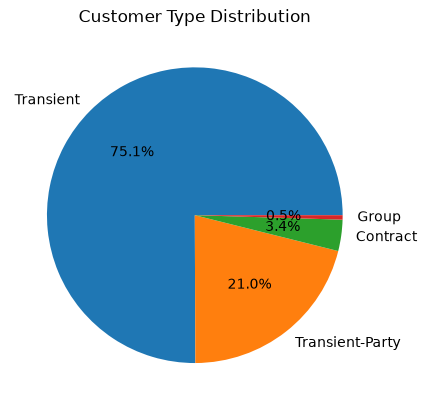

In [22]:
#Customer type
customer_type=df["customer_type"].value_counts()
plt.pie(customer_type,labels=customer_type.index,autopct="%1.1f%%")
plt.title("Customer Type Distribution")
plt.show()

Transient customer is the group that hotels serves the most.

<Axes: xlabel='deposit_type', ylabel='count'>

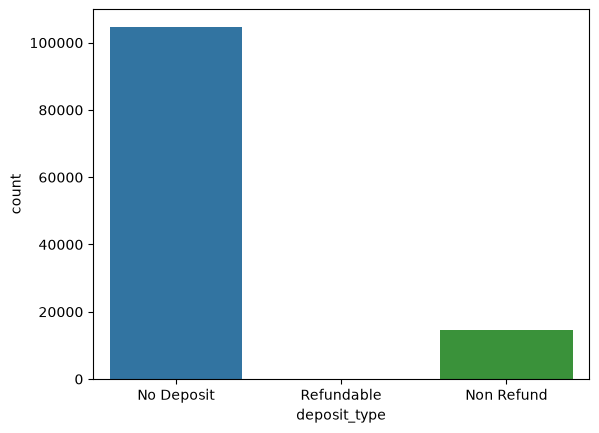

In [23]:
#Deposit Type
sns.countplot(df,x="deposit_type",hue="deposit_type")

No deposit type is used the most by hotels. But would it suggest that this policy will create losses for hotels?

In [24]:
#CUSTOMER LOYALTY
df["is_repeated_guest"].value_counts()

is_repeated_guest
0    115580
1      3810
Name: count, dtype: int64

In [25]:
df["previous_cancellations"].value_counts()

previous_cancellations
0     112906
1       6051
2        116
3         65
24        48
11        35
4         31
26        26
25        25
6         22
19        19
5         19
14        14
13        12
21         1
Name: count, dtype: int64

Suggests that most guests have no prior cancellations. However, small subset shows REPEATED behavior of cancellation.

The result suggest limited customer retention, most bookings are made by first-time customer. It might suggest that most of the hotels surveyed aren't luxury hotels (correlate with income elasticity of customers)

#BIVARIATE ANALYSIS

1. Lead time and Cancellation

<Axes: xlabel='is_canceled', ylabel='lead_time'>

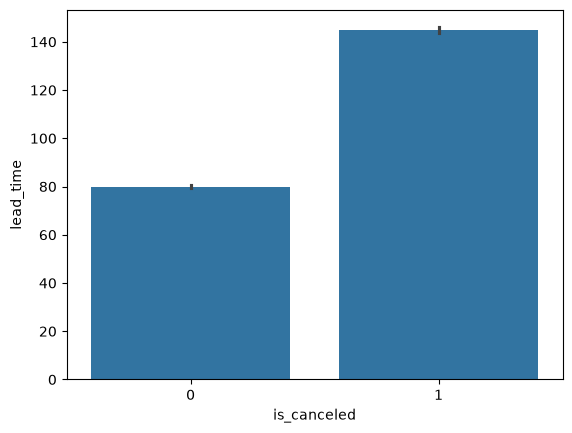

In [26]:
sns.barplot(
    y='lead_time',
    x='is_canceled',
    data=df
)

The plot shows that customers who book in advanced from 80 - 140 days usually cancel their booking. A hypothesis accounts for the phenomenon might be unexpected events occuring on the check-in day after the booking.
One factor might lead to cancellation: longer lead time

2. Deposite type and Cancellation

In [27]:
pd.crosstab(
    df['deposit_type'],
    df['is_canceled'],
    normalize='index'
).rename(columns={"0":"Not Canceled","1":"Canceled"})

is_canceled,Not Canceled,Canceled
deposit_type,,
No Deposit,0.716230,0.283770
Non Refund,0.006376,0.993624
Refundable,0.777778,0.222222


- Customers completing the booking with non-refund deposit type are strongly correlated with cancellation, which gives a worht-looking insight because those customers will lose money when they cancel. (0.99)
- While for "No Deposit" and "Refundable" deposit types, customers are less likely to cancel the booking
--> Why are there this contradiction to the common situation? Might it be that the cancellation of non-refund customers type is held mainly in a large-scale booking?

Let's do a quick multi-variate analysis to see if it is true by crosstabing three variables "market_segment" - "deposit_type" - "is_canceled"

In [51]:
pd.crosstab(
    [df_org['market_segment'], df_org['deposit_type']],
    df_org['is_canceled'],
    normalize='index'
).rename(columns={0:"Not Canceled", 1:"Canceled"})

is_canceled                  Not Canceled  Canceled
market_segment deposit_type                        
Aviation       No Deposit        0.780591  0.219409
Complementary  No Deposit        0.869448  0.130552
Corporate      No Deposit        0.863022  0.136978
               Non Refund        0.065868  0.934132
               Refundable        0.750000  0.250000
Direct         No Deposit        0.847707  0.152293
               Non Refund        0.157895  0.842105
               Refundable        0.666667  0.333333
Groups         No Deposit        0.717004  0.282996
               Non Refund        0.006760  0.993240
               Refundable        0.900000  0.100000
Offline TA/TO  No Deposit        0.827893  0.172107
               Non Refund        0.000599  0.999401
               Refundable        0.500000  0.500000
Online TA      No Deposit        0.633566  0.366434
               Non Refund        0.053571  0.946429
               Refundable        0.000000  1.000000
Undefined      No Deposit        0.000000  1.000000

As it is shown here, the "Groups" booking segment with "Non Refund" deposite types exhibits strongest correlation with cancellation. Besides, the "Coporate" (93.4%), "Offline TA" (99.9%) and "Online TA" (94.6%) also exhibit similiar trend. Noticeably, online TA with "Refundable" deposit type exhibit perfect positive correlation with cancellation, this seems suspicious so let's check the group size.

In [56]:
pd.crosstab(df_org['market_segment'], df_org['deposit_type'], margins=True)

deposit_type,No Deposit,Non Refund,Refundable,All
market_segment,,,,
Aviation,237,0,0,237
Complementary,743,0,0,743
Corporate,4957,334,4,5295
Direct,12581,19,6,12606
Groups,10509,9172,130,19811
Offline TA/TO,19209,5006,4,24219
Online TA,56403,56,18,56477
Undefined,2,0,0,2
All,104641,14587,162,119390


The customer group that book through "Online TA" and has a "Refundable" deposit type is extremely small compared to other elements in the table, so (n = 18 out of 119,390 bookings), so its 100% cancellation rate is not statistically reliable and should not be interpreted as a meaningful pattern.

In [66]:
#Rename the the is_canceled column values to more descriptive names
df["is_canceled"]=df["is_canceled"].replace({"0": "Not Canceled", "1": "Canceled"})
df["is_canceled"]

0         Not Canceled
1         Not Canceled
2         Not Canceled
3         Not Canceled
4         Not Canceled
              ...     
119385    Not Canceled
119386    Not Canceled
119387    Not Canceled
119388    Not Canceled
119389    Not Canceled
Name: is_canceled, Length: 119390, dtype: str

3. Market Segment and Cancellation

<Axes: xlabel='market_segment', ylabel='count'>

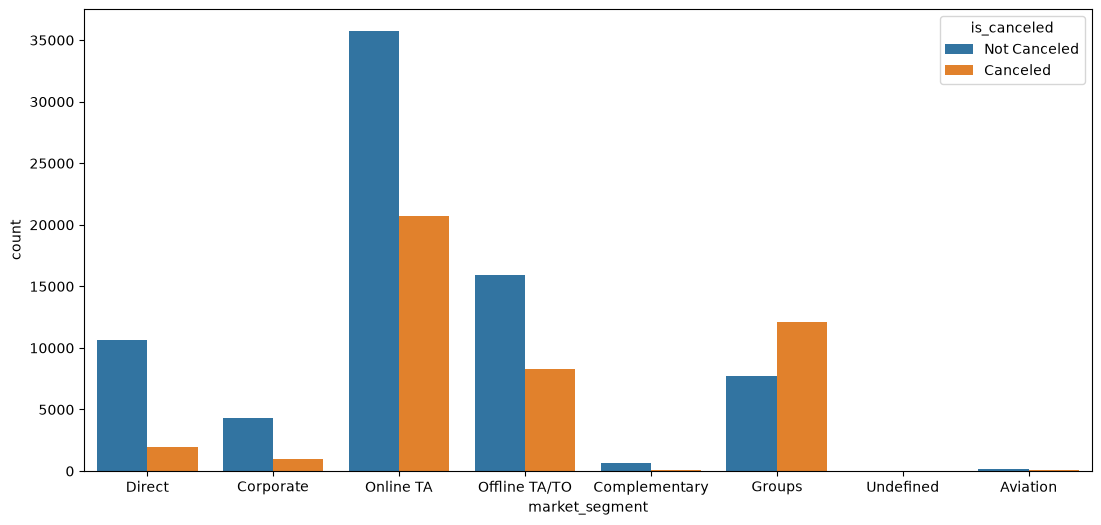

In [67]:
plt.figure(figsize=(13,6))
sns.countplot(x="market_segment",hue="is_canceled",data=df)

In [68]:
pd.crosstab(df["market_segment"],df["is_canceled"],normalize="index")

is_canceled,Canceled,Not Canceled
market_segment,,
Aviation,0.219409,0.780591
Complementary,0.130552,0.869448
Corporate,0.187347,0.812653
Direct,0.153419,0.846581
Groups,0.610620,0.389380
Offline TA/TO,0.343160,0.656840
Online TA,0.367211,0.632789
Undefined,1.000000,0.000000


(With the help of the count graph and the correlation coefficient table, we can observe and detect more reliable correlation)
- "Groups" is the only segment that the bookings got cancelled more than it keeps. About 61% of it is cancelled. 
- Online and offline TA establish 34-36% of cancellation
- Aviation, COmplementary, Coporate and Direct segment are the most reliable, with cancellation rate of under 22%

4. Arrival time of the year and Cancellation

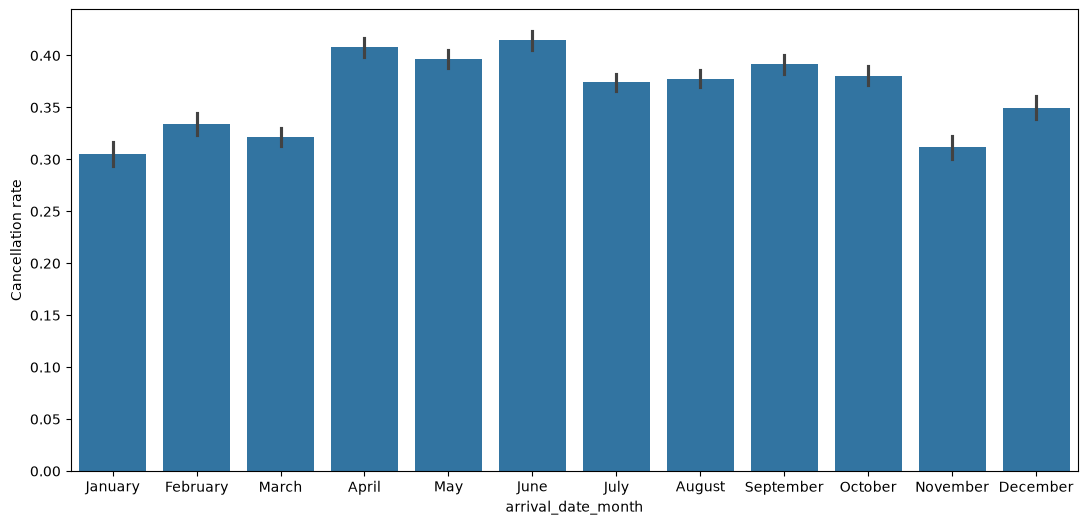

In [ ]:
#Reorder the months to be in chronological order
month_order = ['January','February','March','April','May','June',
               'July','August','September','October','November','December']
#Converting the text labels of the is_canceled column to 0/1 values for plotting cancellation rate
df_plot = df.assign(canceled=(df['is_canceled'] == 'Canceled').astype(int))

plt.figure(figsize=(13, 6))
sns.barplot(x='arrival_date_month', y='canceled', data=df_plot, order=month_order)
plt.ylabel('Cancellation rate')
plt.show()

In [80]:
pd.crosstab(df["arrival_date_month"],df["is_canceled"],values=df["lead_time"],aggfunc='mean')

is_canceled,Canceled,Not Canceled
arrival_date_month,,
April,123.551061,75.026047
August,159.308265,97.987034
December,120.425559,48.359492
February,78.294881,32.585257
January,87.888213,26.644590
July,166.493463,118.255840
June,153.257993,110.535915
March,106.174341,53.033108
May,150.396408,96.114985


In [ ]:
#For cancellation rate
df_plot = df.assign(canceled=(df['is_canceled'] == 'Canceled').astype(int))

month_order = ['January','February','March','April','May','June',
               'July','August','September','October','November','December']
#Calculate several statistics at once by using agg.
summary = (df_plot.groupby('arrival_date_month')
                  .agg(cancel_rate=('canceled', 'mean'),
                       avg_lead_time=('lead_time', 'mean'),
                       median_lead_time=('lead_time', 'median'), #median lead time is a better measure of central tendency for skewed data
                       n=('canceled', 'size'))
                  .reindex(month_order))
summary

,cancel_rate,avg_lead_time,median_lead_time,n
arrival_date_month,,,,
January,0.304773,45.310002,20.0,5929
February,0.334160,47.859569,24.0,8068
March,0.321523,70.119257,46.0,9794
April,0.407972,94.822888,80.0,11089
May,0.396658,117.646171,100.0,11791
June,0.414572,128.247280,118.0,10939
July,0.374536,136.322565,127.0,12661
August,0.377531,121.137710,103.0,13877
September,0.391702,136.675200,86.0,10508


- April, May, Jun (and maybe September) - spring and early summer establish the highest cancellation rate of 39-41%, while the rest of summer to autumn remains in 37-39% of cancellation.  
- January, March, November - winter and early spring shows lowest rate of cancellation
!: This indicates a seasonal pattern for cancellation
?: Lead time can be closely related to seasonal pattern for cancellation  

CONCLUSION:
- In overall,
- Specifically, based on the small multivariate analysis we have done when observing the correlation between customer_type and cancellation, we also discover that Offline TA and Groups bookings take up most of the Non-Refund deposit type, in which the Non-Deposit type establish the higest correlation with cancellation. This implicitly indicates a chance of correlation among customer_type, deposit_type and cancellation that we will discover in the multivariate analysis own section.

In [29]:
#3. Major - Sleep quality
plt.figure(figsize=(13,6))
sns.barplot(x="major_category",y="sleep_quality_score",data=df,alpha=0.5)

ValueError: Could not interpret value `major_category` for `x`. An entry with this name does not appear in `data`.

<Figure size 1300x600 with 0 Axes>

<Axes: xlabel='major_category', ylabel='sleep_quality_score'>

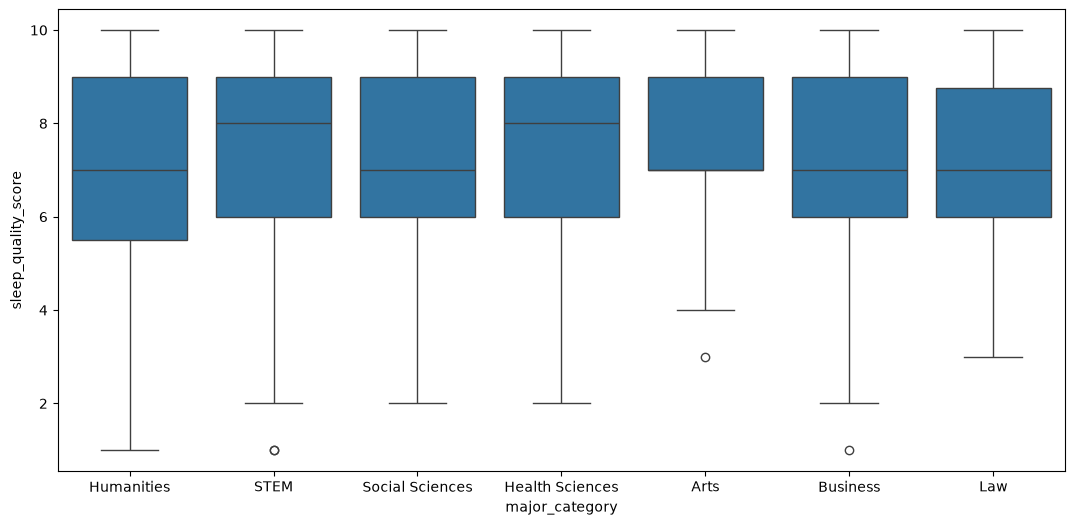

In [ ]:
plt.figure(figsize=(13,6))
sns.boxplot(x="major_category",y="sleep_quality_score",data=df)

Using a boxplot gives more insights than a barplot
- The median varies between the majors: The highest sleep quality score belongs to STEM, Health Science and Arts, while mostly other majors presents a similiar sleep score around 7
- The box overlaps HEAVILY, so major category does not strongly influence sleep quality
- Most students report good sleep quality, with scores commonly between 6 and 10

<Axes: xlabel='major_category', ylabel='count'>

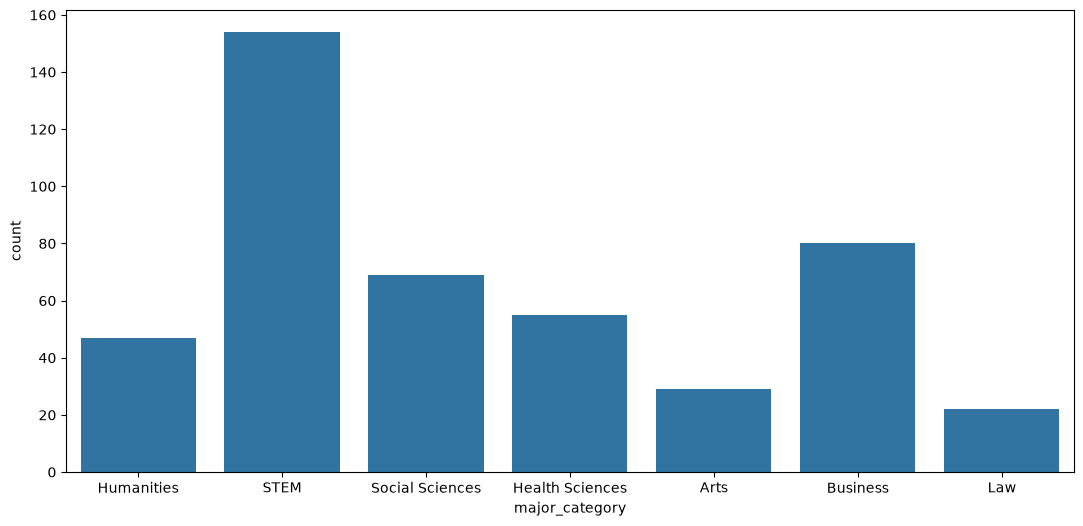

In [ ]:
plt.figure(figsize=(13,6))
sns.countplot(data=df, x='major_category')

- The count plot indicates that STEM students constitute the largest group in the dataset (approximately 155 observations), while Law and Arts are the smallest groups. 
- Despite these differences in sample size, the boxplots reveal substantial overlap in sleep quality distributions across all majors. STEM, Health Sciences, and Arts exhibit slightly higher median sleep quality scores, but the differences are modest.
- Conclusion: Major, alone, does not determine sleep characteristics

<Figure size 1300x600 with 0 Axes>

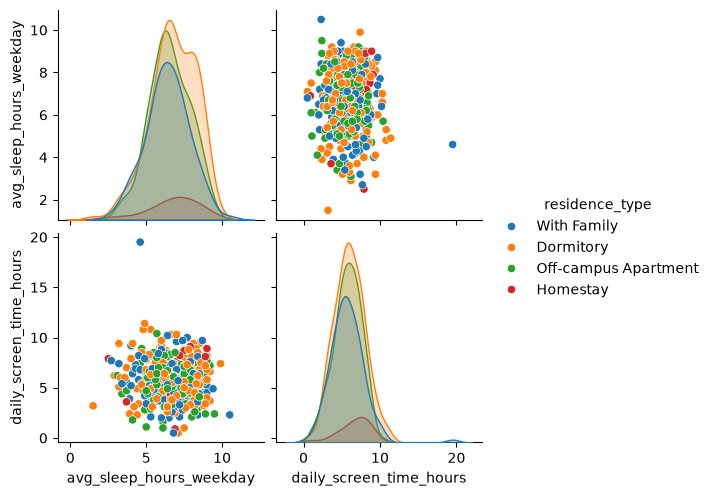

In [ ]:
#2. Residence type - Sleep duration - Screen time
plt.figure(figsize=(13,6))
sns.pairplot(data=df,vars=["avg_sleep_hours_weekday","daily_screen_time_hours"],hue="residence_type")